# Predicting 30-Day Hospital Readmissions

**Dataset:** Diabetes 130-US Hospitals (1999-2008), UCI Machine Learning Repository. About 101k inpatient encounters from 130 US hospitals.

**Goal:** Predict whether a patient will be readmitted within 30 days of discharge.

**Why it matters:** (in your own words: why readmissions matter to hospitals, and why this interests you)

### Step 1: Load the data
**What:** Load the CSV into a pandas DataFrame and take a first look.

**Why:** Before cleaning or modeling, I need to know how big the data is, what the columns are, and what types they hold.

**What I found:** The dataset has 101,766 rows and 50 columns, and most columns are text. `info()` showed zero missing values, but `describe()` revealed that missing values are actually stored as "?" (weight is "?" in 98,569 rows). Also, `citoglipton` has only one value ("No") for every patient, so it adds nothing and will be dropped later.

In [39]:
from pathlib import Path
import pandas as pd

# path to the data folder, relative to this notebook
DATA_DIR = Path("../data")

# main dataset: one row per hospital encounter
df = pd.read_csv(DATA_DIR / "diabetic_data.csv")
df.shape

(101766, 50)

In [40]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype
---  ------                    --------------   -----
 0   encounter_id              101766 non-null  int64
 1   patient_nbr               101766 non-null  int64
 2   race                      101766 non-null  str  
 3   gender                    101766 non-null  str  
 4   age                       101766 non-null  str  
 5   weight                    101766 non-null  str  
 6   admission_type_id         101766 non-null  int64
 7   discharge_disposition_id  101766 non-null  int64
 8   admission_source_id       101766 non-null  int64
 9   time_in_hospital          101766 non-null  int64
 10  payer_code                101766 non-null  str  
 11  medical_specialty         101766 non-null  str  
 12  num_lab_procedures        101766 non-null  int64
 13  num_procedures            101766 non-null  int64
 14  num_medications           10176

In [41]:
df.describe(include="all")

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
count,1.017660e+05,1.017660e+05,101766,101766,101766,101766,101766.000000,101766.000000,101766.000000,101766.000000,...,101766,101766,101766,101766,101766,101766,101766,101766,101766,101766
unique,NaN,NaN,6,3,10,10,NaN,NaN,NaN,NaN,...,1,4,4,2,2,2,2,2,2,3
top,NaN,NaN,Caucasian,Female,[70-80),?,NaN,NaN,NaN,NaN,...,No,No,No,No,No,No,No,No,Yes,NO
freq,NaN,NaN,76099,54708,26068,98569,NaN,NaN,NaN,NaN,...,101766,47383,101060,101753,101765,101764,101765,54755,78363,54864
mean,1.652016e+08,5.433040e+07,NaN,NaN,NaN,NaN,2.024006,3.715642,5.754437,4.395987,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,1.026403e+08,3.869636e+07,NaN,NaN,NaN,NaN,1.445403,5.280166,4.064081,2.985108,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,1.252200e+04,1.350000e+02,NaN,NaN,NaN,NaN,1.000000,1.000000,1.000000,1.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,8.496119e+07,2.341322e+07,NaN,NaN,NaN,NaN,1.000000,1.000000,1.000000,2.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,1.523890e+08,4.550514e+07,NaN,NaN,NaN,NaN,1.000000,1.000000,7.000000,4.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,2.302709e+08,8.754595e+07,NaN,NaN,NaN,NaN,3.000000,4.000000,7.000000,6.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Step 2: Find the real missing values
**What:** Reload the data treating "?" as missing, then count missing values per column.

**Why:** The dataset marks missing values with "?", so pandas didn't recognize them. I need to know which columns have gaps before deciding how to handle them.

**What I found:** Seven columns have real missing values: `weight` **(96.9%)**, `medical_specialty` **(49.1%)**, `payer_code` **(39.6%)**, `race` **(2.2%)**, `diag_3` **(1.4%)**, `diag_2` **(0.4%)**, and `diag_1` **(21 rows)**. All of them are text columns. A1Cresult and max_glu_serum first looked mostly missing, but their "None" value means "test not done," so I told pandas to keep it as a real category.

In [42]:
df = pd.read_csv(DATA_DIR / "diabetic_data.csv", na_values="?", keep_default_na=False, low_memory=False)

# percent missing per column, only showing columns that have any
missing_pct = (df.isna().sum() / len(df) * 100).round(1)
missing_pct[missing_pct > 0].sort_values(ascending=False)

weight               96.9
medical_specialty    49.1
payer_code           39.6
race                  2.2
diag_3                1.4
diag_2                0.4
dtype: float64

### Step 3: Handle missing values

**What:** Drop weight and fill the other missing text columns with "Unknown".

**Why:** Weight is too empty to use. For the rest, **"Unknown"** keeps the rows without making anything up. `diag_1` is the main diagnosis, so I just dropped the 21 rows missing it.

**What I found:** No missing values left.

In [43]:
# weight is ~97% missing, not worth keeping
df = df.drop(columns=["weight"])

# fill remaining missing text values with "Unknown"
fill_cols = ["medical_specialty", "payer_code", "race", "diag_2", "diag_3"]
df[fill_cols] = df[fill_cols].fillna("Unknown")

# drop 21 rows with no primary diagnosis (negligible loss)
df = df.dropna(subset=["diag_1"])

### Step 4: Remove rows that don't belong
**What:** Remove patients who died or went to hospice, and keep only each patient's first visit.

**Why:** Patients who died or went to hospice can't come back, so they'd skew the model. Repeat patients could end up in both train and test, so I kept each person's first visit.

**What I found:** Down to [99,343] rows after removing death/hospice, then [69,990] after dropping [29,353] repeat visits.

In [44]:
# discharge codes for patients who died or went to hospice bc they can't be readmitted
exclude_ids = [11, 13, 14, 19, 20, 21]

df = df[~df["discharge_disposition_id"].isin(exclude_ids)]
df.shape

(99323, 49)

In [45]:
# how many repeat visits are there?
df["patient_nbr"].duplicated().sum()

np.int64(29341)

In [46]:
# keep each patient's first encounter so the same person can't be in both train and test
df = df.sort_values("encounter_id").drop_duplicates(subset="patient_nbr", keep="first")
df.shape

(69982, 49)

### Step 5: Create the target and check class balance
**What:** Turn "readmitted" into a yes/no column for readmission within 30 days, then check how balanced it is.

**Why:** The original column has three values (<30, >30, NO), but the question is specifically about 30-day readmission, so I turned it into yes/no. Checking balance tells me whether accuracy will be misleading.

**What I found:** Only about 9% of patients were readmitted within 30 days. A model that always guesses "No" would achieve a 91% accuracy while catching zero readmissions.

In [47]:
# 1 = readmitted within 30 days, 0 = not (">30" and "NO" both count as 0)
df["readmit_30"] = (df["readmitted"] == "<30").astype(int)
df = df.drop(columns=["readmitted"])

In [48]:
# share of each class
df["readmit_30"].value_counts(normalize=True)

readmit_30
0    0.91022
1    0.08978
Name: proportion, dtype: float64

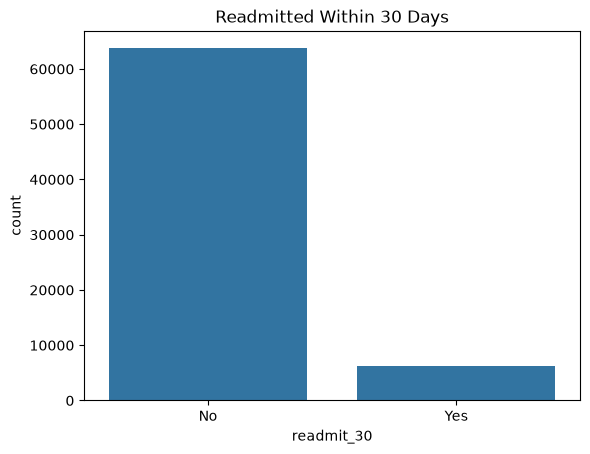

In [49]:
# bar chart of the class balance
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(x="readmit_30", data=df)
plt.title("Readmitted Within 30 Days")
plt.xticks([0, 1], ["No", "Yes"])
plt.savefig("../images/class_balance.png", bbox_inches="tight")
plt.show()